# Experiments: train + evaluate + explain ONE model (Steps 4–6)

Every experiment becomes **one MLflow run** on DagsHub containing:
- the resolved config, all hyper-parameters, git commit and dataset digest
- GPU/CPU usage, and per-epoch loss, learning rate and validation AUROC for every label
- the best checkpoint and the PyTorch model
- the test evaluation: calibration, uncertainty band, figures and report
- the Grad-CAM localisation scores and gallery

**How to use:** set `EXPERIMENT` below, then **Save Version → Save & Run All**. Run one commit per experiment (each stays well under Kaggle's 12 h limit).

**Settings:** GPU T4 x2, Internet ON. **Inputs:** NIH Chest X-rays dataset + your Phase 1 notebook. **Secrets (required here):** `MLFLOW_TRACKING_URI`, `MLFLOW_TRACKING_USERNAME`, `MLFLOW_TRACKING_PASSWORD`, attached to this notebook. DagsHub is what lets runs from different commits be compared.

| Experiment | What it tests | Approx. time on T4 |
|---|---|---|
| `densenet121_224` | baseline (CheXNet-style) | 2 h |
| `densenet121_320` | + resolution + modern recipe (cosine, label smoothing, EMA) | 4 h |
| `convnext_tiny_320` | modern CNN backbone | 4 h |
| `efficientnet_v2_s_320` | efficient backbone | 3–4 h |


In [1]:
EXPERIMENT = "densenet121_320"      # <- change for each commit
REPO_URL   = "https://github.com/mayartahri3/MedVision.git"
RUN_SMOKE  = True                    # 2-minute check before the long run

In [2]:
!git clone -q $REPO_URL MedVision
%cd MedVision
!pip install -q monai pydicom tabulate mlflow
!git log -1 --oneline
!python scripts/train.py --list

/kaggle/working/MedVision
e3e259a (HEAD -> main, origin/main, origin/HEAD) Merge branch 'main' of https://github.com/mayartahri3/MedVision
I0000 00:00:1795646717.677518      73 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
densenet121_224          Baseline: DenseNet-121 (CheXNet-style), 224 px, ReduceLROnPlateau
densenet121_320          DenseNet-121 at 320 px, cosine LR + warm-up, label smoothing, EMA
convnext_tiny_320        ConvNeXt-Tiny at 320 px, same recipe as E2
efficientnet_v2_s_320    EfficientNetV2-S at 320 px, same recipe as E2


In [3]:
import os
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
from kaggle_secrets import UserSecretsClient
s = UserSecretsClient()
for k in ("MLFLOW_TRACKING_URI", "MLFLOW_TRACKING_USERNAME", "MLFLOW_TRACKING_PASSWORD"):
    os.environ[k] = s.get_secret(k)          # fails loudly if a secret is missing / not attached
print("MLflow ->", os.environ["MLFLOW_TRACKING_URI"])

MLflow -> https://dagshub.com/mayartahri3/MedVision.mlflow


## Link the Phase 1 output (unzips the image cache to /tmp)

In [4]:
!python scripts/link_phase1.py

Extracting /kaggle/input/notebooks/mayartahri/01-phase1-kaggle/_output_.zip (5.6 GB) -> /tmp/phase1_output ...
splits.csv : /tmp/phase1_output/MedVision/data/processed/splits.csv
image cache: /tmp/phase1_output/cache/images_320
cache hit rate on 200 random images: 100%
Linked -> /kaggle/working/MedVision/data/processed/splits.csv (112,120 rows)


## Smoke test (a separate MLflow run tagged smoke_test=true; the comparison ignores it)

In [5]:
if RUN_SMOKE:
    !python scripts/train.py --experiment $EXPERIMENT --smoke --epochs 1 --max-steps 20 --subset 640

I0000 00:00:1795646883.713311     104 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Experiment: densenet121_320-smoke | device: cuda | model: densenet121 | 320 px | 15 labels
{'train': 640, 'val': 640, 'test': 640}
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth
100%|██████████████████████████████████████| 30.8M/30.8M [00:00<00:00, 79.2MB/s]
2026/11/25 22:48:15 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
MLflow run: fada3194ffca4dcfabb42771691f5acf (https://dagshub.com/mayartahri3/MedVision.mlflow)
/usr/local/lib/python3.13/dist-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. 

## Step 4: train

In [6]:
!python scripts/train.py --experiment $EXPERIMENT

I0000 00:00:1795646995.598798     191 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Experiment: densenet121_320 | device: cuda | model: densenet121 | 320 px | 15 labels
{'train': 77719, 'val': 8805, 'test': 25596}
2026/11/25 22:50:01 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
MLflow run: e10accf0f5ac47bcb1051172a2130fcb (https://dagshub.com/mayartahri3/MedVision.mlflow)
/usr/local/lib/python3.13/dist-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) wheneve

## Step 5: evaluate (same MLflow run)

In [7]:
!python scripts/evaluate.py --experiment $EXPERIMENT

I0000 00:00:1795654246.835102     550 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
densenet121_320: densenet121 @ 320 px, epoch 4, val mean AUROC 0.8574
TTA: 0.8254 -> 0.8257
2026/11/26 01:01:05 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
🏃 View run densenet121_320 at: https://dagshub.com/mayartahri3/MedVision.mlflow/#/experiments/0/runs/e10accf0f5ac47bcb1051172a2130fcb
🧪 View experiment at: https://dagshub.com/mayartahri3/MedVision.mlflow/#/experiments/0
2026/11/26 01:02:12 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/26 01:02:12 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!
test_mean_auroc_14                 0.8257
test_mean_auroc_focus              0.7994
test_mean_ece_calibrated           0.0155
uncertain_per_image_focus          1.4674
pct_images_any_uncertain_focus     0.8367
Outputs -> /kagg

## Step 6: Grad-CAM (same MLflow run)

In [8]:
!python scripts/gradcam_eval.py --experiment $EXPERIMENT --split test

I0000 00:00:1795654955.201956     650 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Boxes per split: {'test': 984}
                  n  pointing_acc  centre_baseline  energy_in_box  box_area
label                                                                      
Atelectasis   180.0         0.428            0.078          0.136     0.033
Cardiomegaly  146.0         1.000            0.986          0.644     0.178
Effusion      153.0         0.458            0.033          0.216     0.070
Infiltration  123.0         0.602            0.252          0.251     0.098
Mass           85.0         0.353            0.118          0.189     0.043
Nodule         79.0         0.089            0.000          0.030     0.006
Pneumonia     120.0         0.708            0.158          0.238     0.096
Pneumothorax   98.0         0.204            0.020          0.129     0.053
ALL           984.0         0.517            0.229          0.246     0.077
2026/11/2

## Results

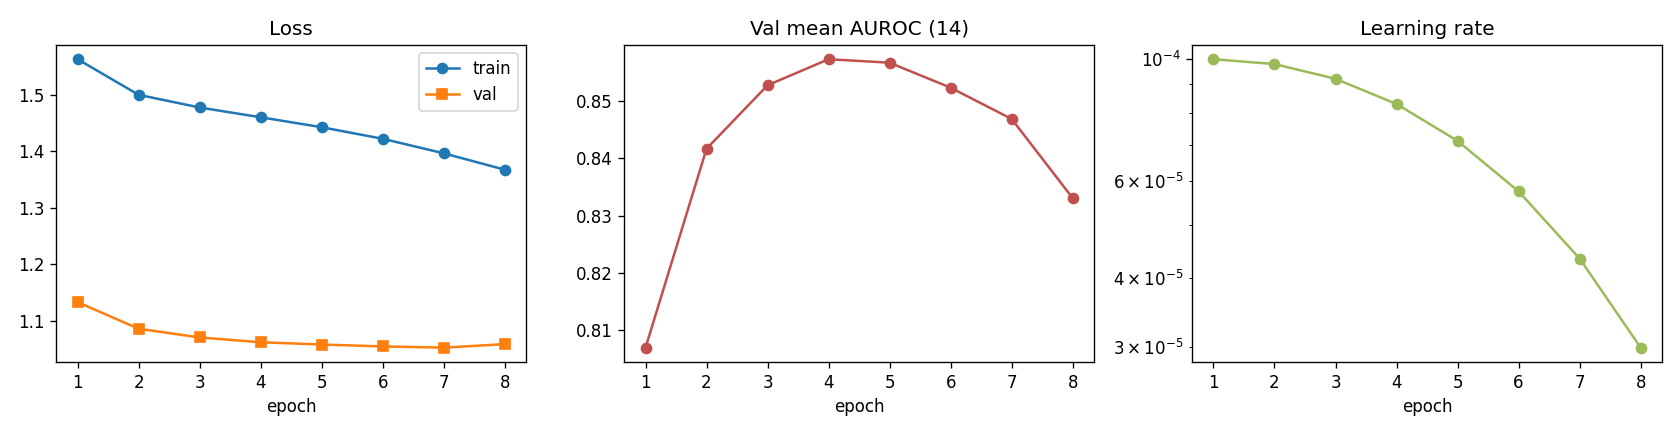

# Evaluation report - densenet121_320

Model: densenet121 | image size: 320 | TTA: True | best epoch: 4

**Test mean AUROC (14 NIH labels): 0.8257**  
Test mean AUROC (focus labels): 0.7994  
Mean calibration error: 0.515 raw -> 0.015 calibrated

## Decision policy (fitted on validation only)

- p < t_low -> **negative**: t_low keeps 90% of positives (rule-out).
- p >= t_high -> **positive**: 90% specificity.
- otherwise -> **uncertain** (the report must flag it).
- Per image: 1.47 uncertain focus labels on average; 84% of images have at least one.

## Focus labels

| label        |   n_pos |   auroc |   auroc_ci_low |   auroc_ci_high |   auprc |   sens_positive |   spec_positive |   ppv_positive |   sens_not_negative |   npv_negative |   pct_negative |   pct_uncertain |   pct_positive |   ece_raw |   ece_calibrated |
|:-------------|--------:|--------:|---------------:|----------------:|--------:|----------------:|----------------:|---------------:|--------------------:|---------------:|---------------:|----------------:|---------------:|----------:|-----------------:|
| Pneumonia    |     555 |  0.7328 |         0.7092 |          0.7563 |  0.0582 |          0.564  |          0.7619 |         0.0499 |              0.9171 |         0.9941 |         0.3039 |          0.4509 |         0.2452 |    0.6448 |           0.0057 |
| Cardiomegaly |    1069 |  0.8981 |         0.8829 |          0.9106 |  0.3629 |          0.7428 |          0.8846 |         0.219  |              0.8887 |         0.9933 |         0.6916 |          0.1668 |         0.1416 |    0.6086 |           0.0146 |
| Lung_Opacity |    9843 |  0.7307 |         0.7208 |          0.7409 |  0.5882 |          0.5765 |          0.754  |         0.5942 |              0.9695 |         0.8794 |         0.0972 |          0.5297 |         0.3731 |    0.229  |           0.0282 |
| Effusion     |    4658 |  0.8361 |         0.8267 |          0.8467 |  0.5231 |          0.7022 |          0.8019 |         0.441  |              0.9446 |         0.9742 |         0.3903 |          0.3199 |         0.2898 |    0.3927 |           0.0171 |

## All labels

| label              |   n_pos |   auroc |   auroc_ci_low |   auroc_ci_high |   auprc |   sens_positive |   spec_positive |   ppv_positive |   sens_not_negative |   npv_negative |   pct_negative |   pct_uncertain |   pct_positive |   ece_raw |   ece_calibrated |
|:-------------------|--------:|--------:|---------------:|----------------:|--------:|----------------:|----------------:|---------------:|--------------------:|---------------:|---------------:|----------------:|---------------:|----------:|-----------------:|
| Atelectasis        |    3279 |  0.7877 |         0.7745 |          0.8008 |  0.3628 |          0.4852 |          0.8708 |         0.3555 |              0.9305 |         0.9748 |         0.3535 |          0.4716 |         0.1748 |    0.4006 |           0.0114 |
| Cardiomegaly       |    1069 |  0.8981 |         0.8829 |          0.9106 |  0.3629 |          0.7428 |          0.8846 |         0.219  |              0.8887 |         0.9933 |         0.6916 |          0.1668 |         0.1416 |    0.6086 |           0.0146 |
| Effusion           |    4658 |  0.8361 |         0.8267 |          0.8467 |  0.5231 |          0.7022 |          0.8019 |         0.441  |              0.9446 |         0.9742 |         0.3903 |          0.3199 |         0.2898 |    0.3927 |           0.0171 |
| Infiltration       |    6112 |  0.7106 |         0.7008 |          0.7207 |  0.4041 |          0.6021 |          0.7277 |         0.4096 |              0.9563 |         0.9153 |         0.1232 |          0.5257 |         0.351  |    0.3646 |           0.0274 |
| Mass               |    1748 |  0.8365 |         0.8171 |          0.852  |  0.3398 |          0.7094 |          0.8094 |         0.2143 |              0.9537 |         0.9908 |         0.3456 |          0.4283 |         0.2261 |    0.4659 |           0.0162 |
| Nodule             |    1623 |  0.787  |         0.7696 |          0.8037 |  0.255  |          0.5619 |          0.8489 |         0.2011 |              0.9396 |         0.9862 |         0.2781 |          0.5448 |         0.1772 |    0.4871 |           0.012  |
| Pneumonia          |     555 |  0.7328 |         0.7092 |          0.7563 |  0.0582 |          0.564  |          0.7619 |         0.0499 |              0.9171 |         0.9941 |         0.3039 |          0.4509 |         0.2452 |    0.6448 |           0.0057 |
| Pneumothorax       |    2665 |  0.8777 |         0.8642 |          0.8899 |  0.4287 |          0.8225 |          0.7837 |         0.3064 |              0.9741 |         0.9933 |         0.4005 |          0.3201 |         0.2795 |    0.515  |           0.0379 |
| Consolidation      |    1815 |  0.7574 |         0.7415 |          0.7738 |  0.1702 |          0.5554 |          0.7797 |         0.1614 |              0.9774 |         0.9923 |         0.2076 |          0.5483 |         0.244  |    0.5895 |           0.0161 |
| Edema              |     925 |  0.8528 |         0.837  |          0.8696 |  0.1684 |          0.8076 |          0.7501 |         0.1081 |              0.9503 |         0.9966 |         0.5324 |          0.1975 |         0.2701 |    0.6605 |           0.0126 |
| Emphysema          |    1093 |  0.9366 |         0.9282 |          0.9445 |  0.4618 |          0.9186 |          0.8157 |         0.1819 |              0.9698 |         0.9978 |         0.5883 |          0.196  |         0.2157 |    0.5904 |           0.0166 |
| Fibrosis           |     435 |  0.8323 |         0.8122 |          0.852  |  0.0981 |          0.5609 |          0.8797 |         0.0746 |              0.892  |         0.9966 |         0.5454 |          0.3268 |         0.1278 |    0.6122 |           0.0041 |
| Pleural_Thickening |    1143 |  0.7914 |         0.7739 |          0.8076 |  0.1522 |          0.6535 |          0.7827 |         0.1232 |              0.9475 |         0.9922 |         0.3021 |          0.4611 |         0.2368 |    0.5938 |           0.0098 |
| Hernia             |      86 |  0.9222 |         0.8699 |          0.9559 |  0.3938 |          0.7093 |          0.961  |         0.0577 |              0.7093 |         0.999  |         0.9587 |          0      |         0.0413 |    0.5652 |           0.0022 |
| Lung_Opacity       |    9843 |  0.7307 |         0.7208 |          0.7409 |  0.5882 |          0.5765 |          0.754  |         0.5942 |              0.9695 |         0.8794 |         0.0972 |          0.5297 |         0.3731 |    0.229  |           0.0282 |

## Band width vs target (validation, % uncertain)

|   target |   Atelectasis |   Cardiomegaly |   Effusion |   Infiltration |   Mass |   Nodule |   Pneumonia |   Pneumothorax |   Consolidation |   Edema |   Emphysema |   Fibrosis |   Pleural_Thickening |   Hernia |   Lung_Opacity |
|---------:|--------------:|---------------:|-----------:|---------------:|-------:|---------:|------------:|---------------:|----------------:|--------:|------------:|-----------:|---------------------:|---------:|---------------:|
|     0.8  |         0.054 |          0     |      0     |          0.286 |  0.051 |    0.163 |       0.116 |          0     |           0.094 |   0     |       0     |      0.125 |                0.118 |    0     |          0.222 |
|     0.85 |         0.163 |          0.031 |      0.034 |          0.414 |  0.167 |    0.278 |       0.267 |          0.106 |           0.234 |   0     |       0.003 |      0.223 |                0.284 |    0     |          0.354 |
|     0.9  |         0.3   |          0.141 |      0.161 |          0.544 |  0.319 |    0.428 |       0.406 |          0.306 |           0.41  |   0.125 |       0.212 |      0.327 |                0.444 |    0     |          0.496 |
|     0.95 |         0.5   |          0.28  |      0.328 |          0.725 |  0.576 |    0.655 |       0.59  |          0.451 |           0.593 |   0.319 |       0.407 |      0.522 |                0.641 |    0.435 |          0.679 |

## AUROC by view (PA vs AP)

|                    |     AP |     PA |
|:-------------------|-------:|-------:|
| Atelectasis        | 0.7775 | 0.8013 |
| Cardiomegaly       | 0.8608 | 0.9394 |
| Effusion           | 0.8088 | 0.8683 |
| Infiltration       | 0.6824 | 0.6324 |
| Mass               | 0.8082 | 0.8588 |
| Nodule             | 0.7745 | 0.7961 |
| Pneumonia          | 0.7061 | 0.7358 |
| Pneumothorax       | 0.8671 | 0.8778 |
| Consolidation      | 0.7045 | 0.7639 |
| Edema              | 0.7803 | 0.8667 |
| Emphysema          | 0.9478 | 0.9193 |
| Fibrosis           | 0.8297 | 0.7872 |
| Pleural_Thickening | 0.7884 | 0.7713 |
| Hernia             | 0.9126 | 0.919  |
| Lung_Opacity       | 0.6856 | 0.6995 |

Column guide: sens/spec/ppv_positive = metrics of the 'positive' call; sens_not_negative = share of real cases NOT dismissed as negative; npv_negative = how often a 'negative' call is right.

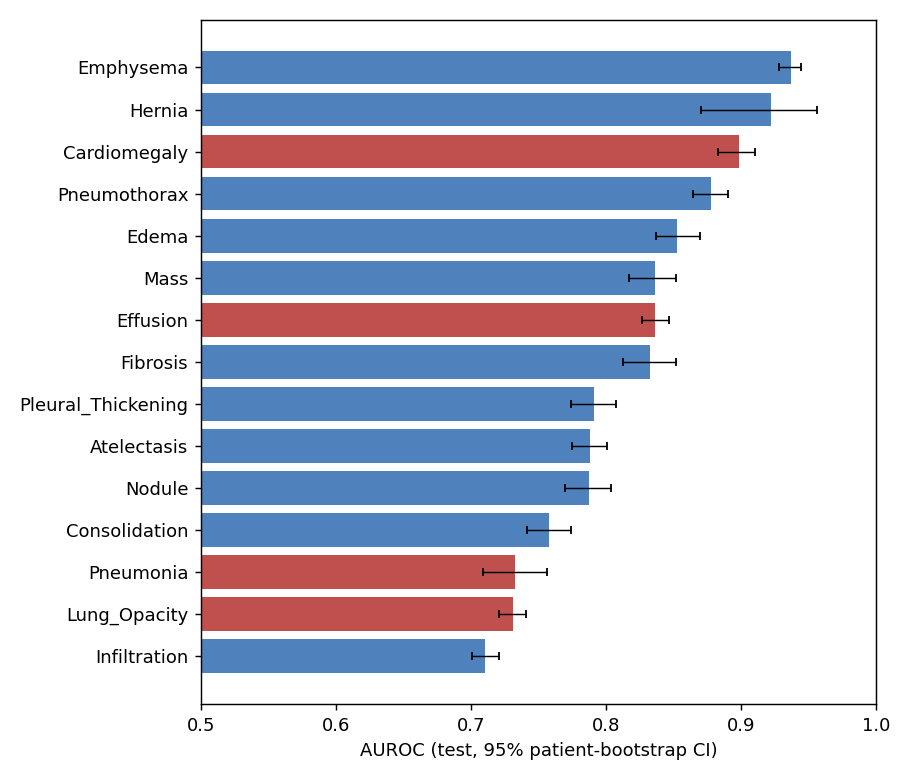

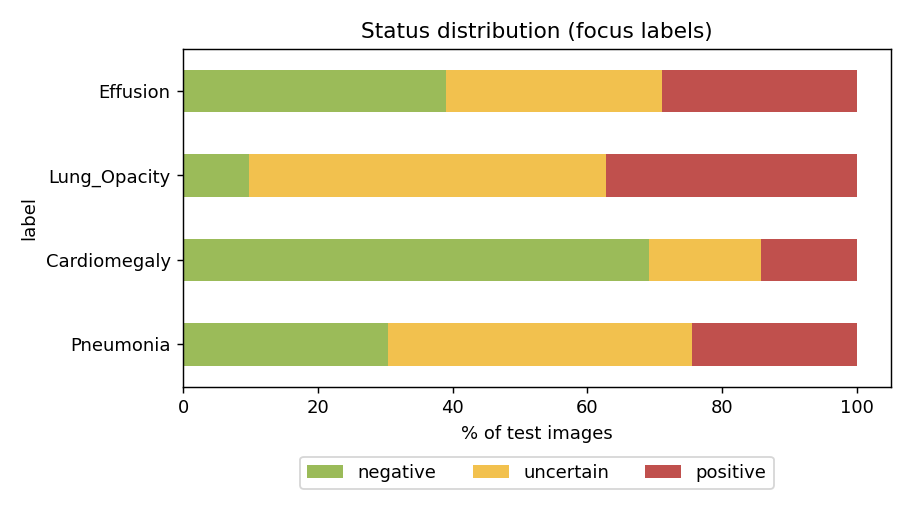

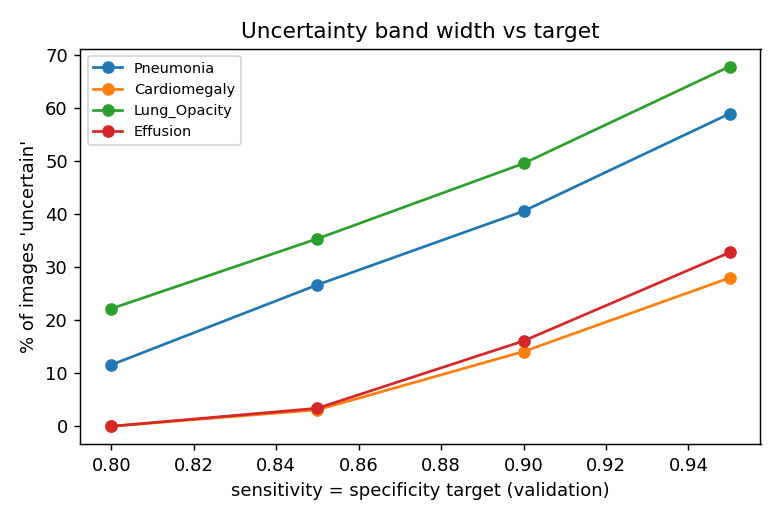

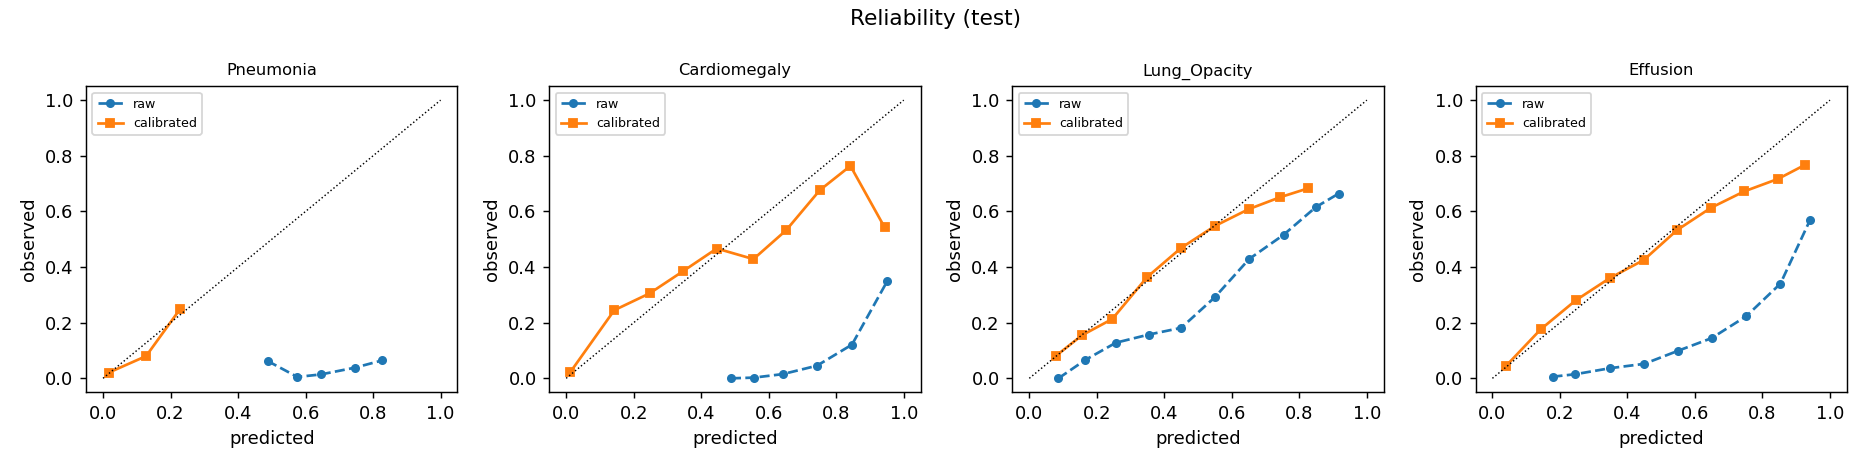

# Grad-CAM localisation (NIH bounding boxes)

Split: test; boxes evaluated: 984; tolerance: 15 px (1024-px space).

| label        |   n |   pointing_acc |   centre_baseline |   energy_in_box |   box_area |
|:-------------|----:|---------------:|------------------:|----------------:|-----------:|
| Atelectasis  | 180 |          0.428 |             0.078 |           0.136 |      0.033 |
| Cardiomegaly | 146 |          1     |             0.986 |           0.644 |      0.178 |
| Effusion     | 153 |          0.458 |             0.033 |           0.216 |      0.07  |
| Infiltration | 123 |          0.602 |             0.252 |           0.251 |      0.098 |
| Mass         |  85 |          0.353 |             0.118 |           0.189 |      0.043 |
| Nodule       |  79 |          0.089 |             0     |           0.03  |      0.006 |
| Pneumonia    | 120 |          0.708 |             0.158 |           0.238 |      0.096 |
| Pneumothorax |  98 |          0.204 |             0.02  |           0.129 |      0.053 |
| ALL          | 984 |          0.517 |             0.229 |           0.246 |      0.077 |

- **pointing_acc**: hottest CAM pixel inside the box.
- **centre_baseline**: same test for a fixed guess at the image centre. Grad-CAM is only informative where it clearly beats this.
- **energy_in_box vs box_area**: if energy is not well above the box's share of the image, the heatmap is diffuse rather than localised.

Grad-CAM shows where the model looked, not proof that its reasoning is correct.

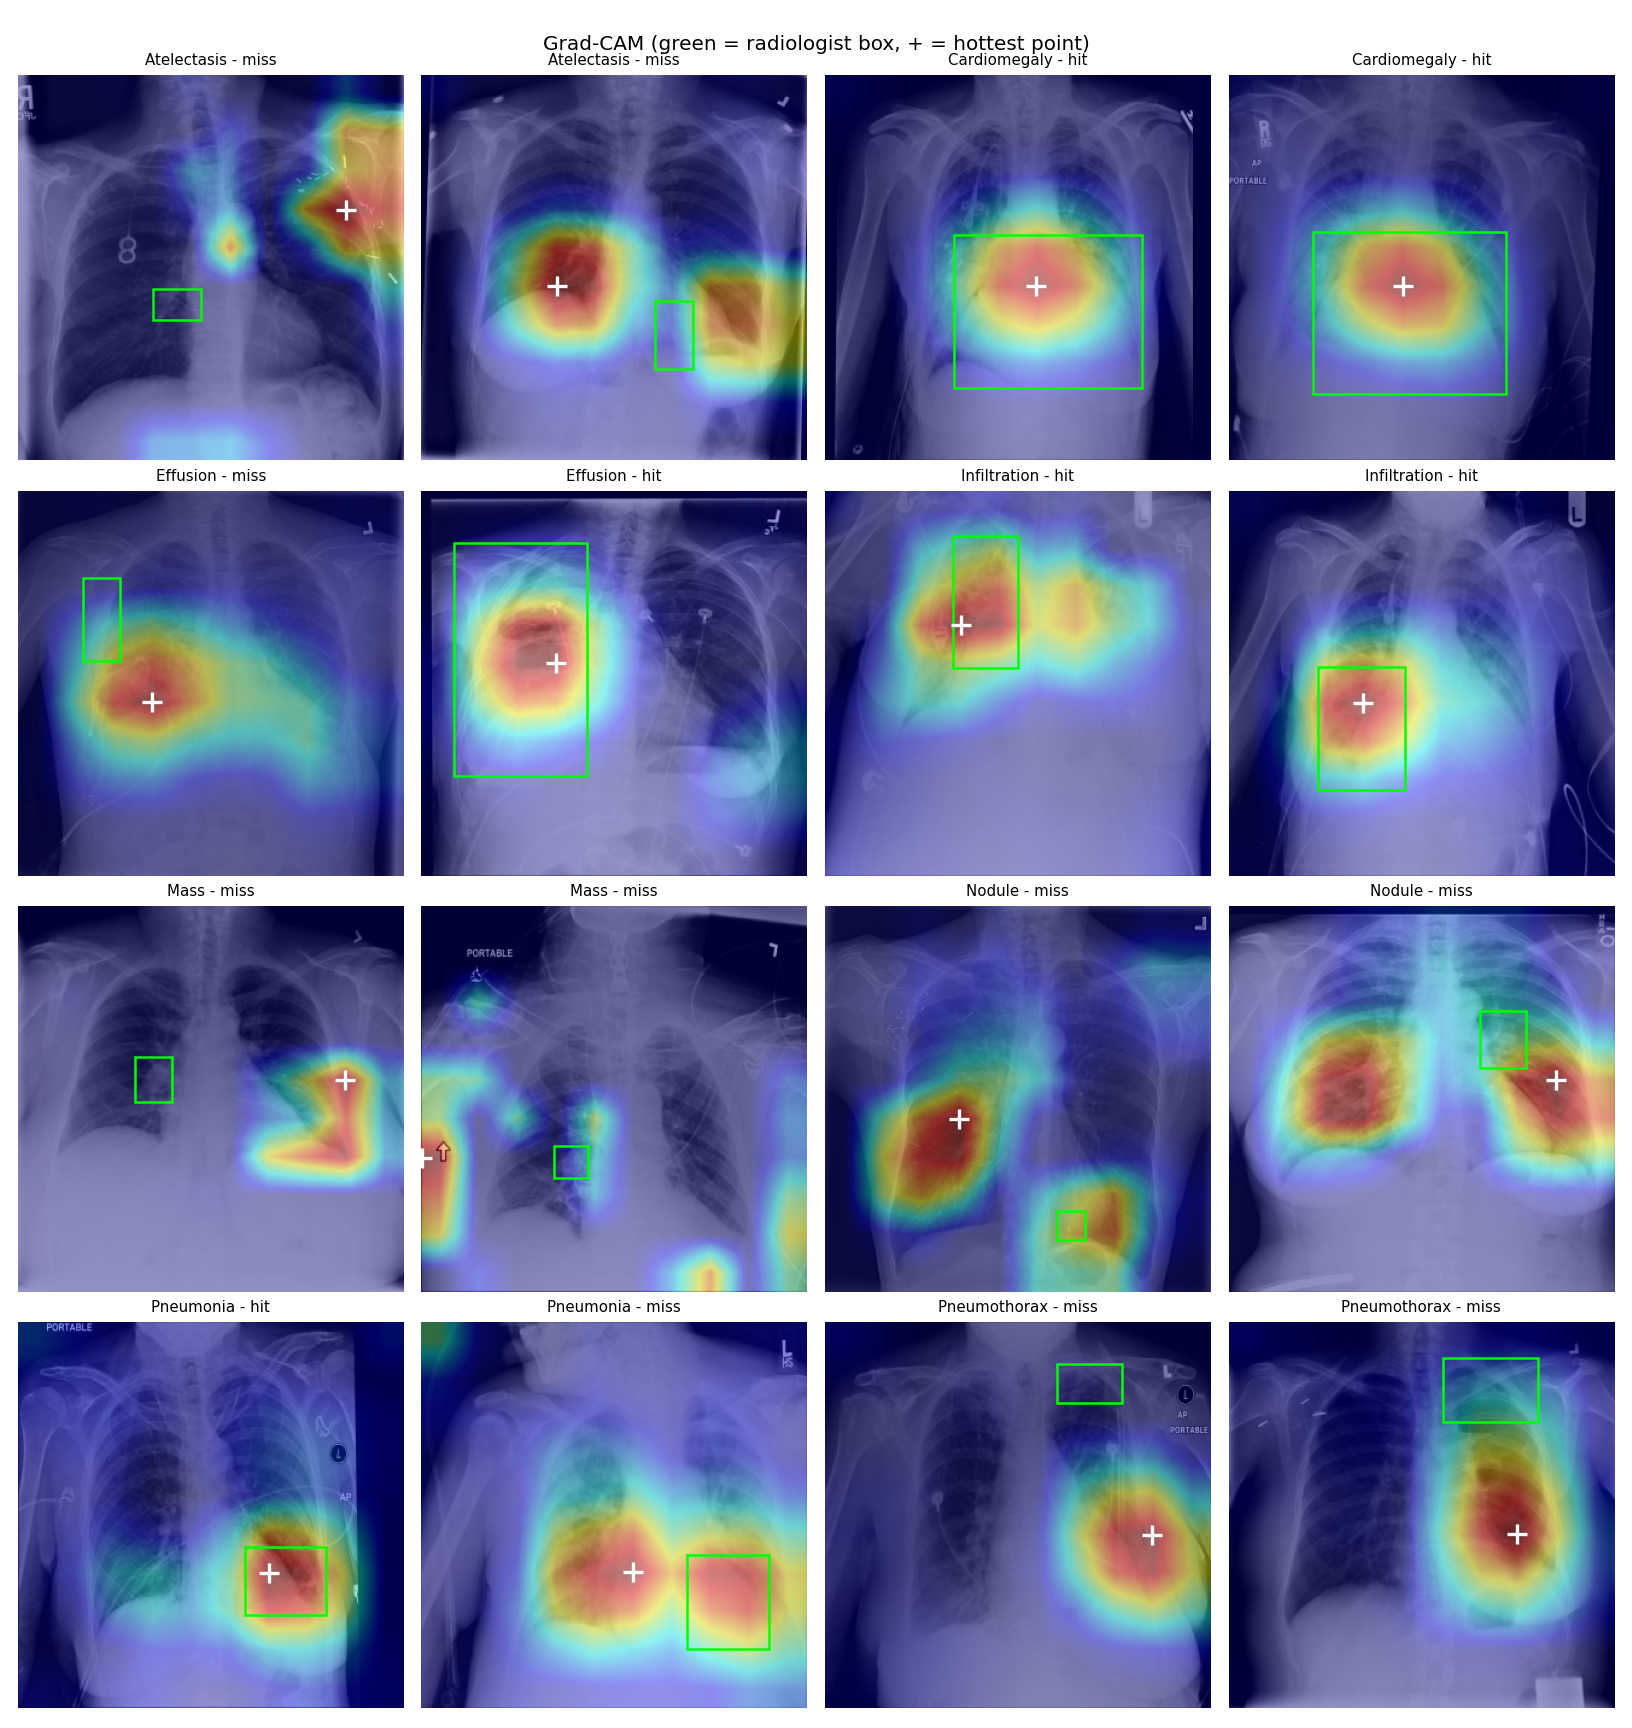

e10accf0f5ac47bcb1051172a2130fcb


In [9]:
from IPython.display import Image, Markdown, display
W = f"/kaggle/working/{EXPERIMENT}"
display(Image(f"{W}/checkpoints/training_curves.png"))
display(Markdown(open(f"{W}/eval/eval_report.md").read()))
for f in ["auroc_ci", "status_focus", "band_sweep", "reliability_focus"]:
    display(Image(f"{W}/eval/{f}.png"))
display(Markdown(open(f"{W}/explain/explain_report.md").read()))
display(Image(f"{W}/explain/gradcam_gallery.png"))
print(open(f"{W}/checkpoints/mlflow_run_id.txt").read())